# ReSnap: demo deteksi + rekomendasi resep

Satu panggilan `scan(foto)` menjalankan preprocessing OpenCV, deteksi YOLOv8 (model v4b), lalu pencocokan resep dari database lokal (14.658 resep Cookpad). Tidak butuh internet. Contoh keluaran tersedia di `contoh/contoh_output.json`.

Jalankan dari folder repo setelah `pip install -r requirements.txt`.

In [1]:
import os, sys
if not os.path.exists('resnap_pipeline.py'):  # notebook dibuka dari folder notebooks/
    os.chdir('..')
sys.path.insert(0, os.getcwd())
print(os.getcwd())

In [2]:
import json
from resnap_pipeline import scan, rekomendasi

hasil = scan('contoh/foto_udang.jpg', conf=0.5, top_k=5, simpan_gambar='contoh/contoh_output.jpg')
print('Bahan:', [(b['nama'], b['jumlah'], b['confidence_maks']) for b in hasil['bahan']])
print('Waktu (ms):', hasil['waktu_ms'])
for r in hasil['resep']:
    print(f"{r['skor']:.0%}  {r['judul']}  | kurang: {', '.join(r['bahan_kurang']) or '-'}")

Bahan: [('Udang', 3, 0.8652)]
Waktu (ms): {'preprocessing': 124, 'deteksi': 1917, 'resep': 320}
50%  Udang Bakar Madu Simple  | kurang: madu
50%  Udang panggang simple 🦐  | kurang: Jeruk nipis
50%  Udang goreng simple  | kurang: Bawang putih
50%  Udang goreng tepung krispi simple  | kurang: tepung krispi mama suka
50%  Butter Garlic Prawn (Udang saus mentega) Non MSG  | kurang: Bawang putih


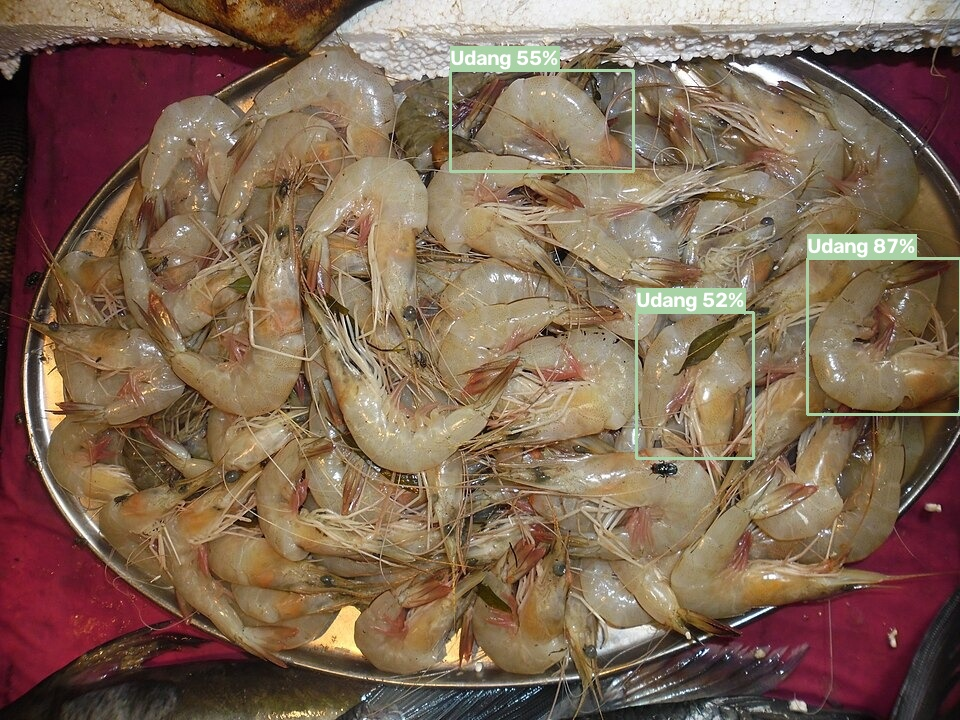

In [3]:
from IPython.display import Image
Image('contoh/contoh_output.jpg', width=600)

Setelah user mengedit daftar bahan di frontend, panggil `rekomendasi()` dengan nama kelas (bukan nama Indonesia). Daftar kelas tersedia di `src/detector.py`.

In [4]:
for r in rekomendasi(['egg', 'tomato', 'shallot', 'chili']):
    print(f"{r['skor']:.0%}  {r['judul']}  | punya: {', '.join(r['bahan_tersedia'])} | kurang: {', '.join(r['bahan_kurang']) or '-'}")

100%  Telor ceplok balado  | punya: Telur, Bawang merah, Cabai, Tomat | kurang: -
100%  Telur ceplok bawang cabe  | punya: Telur, Bawang merah, Cabai, Tomat | kurang: -
100%  Telur Penyet Sambal Kukus  | punya: Telur, Cabai, Tomat | kurang: -
100%  Telur Dadar  | punya: Telur, Cabai, Bawang merah | kurang: -
100%  Orak-arik telor original  | punya: Telur, Bawang merah, Cabai | kurang: -


In [5]:
# Potongan JSON lengkap untuk satu resep
print(json.dumps(hasil['resep'][0], ensure_ascii=False, indent=2)[:1500])

{
  "judul": "Udang Bakar Madu Simple",
  "skor": 0.5,
  "bahan_tersedia": [
    "Udang"
  ],
  "bahan_kurang": [
    "madu"
  ],
  "bahan_resep": [
    "Udang 1/4 kg yang besar",
    "3 sendok makan madu",
    "3 sendok makan saus tomat",
    "3 sendok makan kecap manis",
    "Kaldu bubuk",
    "secukupnya Garam",
    "secukupnya Lada"
  ],
  "langkah": [
    "Cuci udang kalau mau dikasih jeruk nipis oke aja",
    "Campurkan semua saus dan bumbu",
    "Rendam udang dalam bumbu selama 15-30 menit di kulkas",
    "Panggang udang sambil di olesi bumbu dalam wajan grill sampai matang"
  ],
  "kategori": "udang",
  "loves": 58,
  "sumber": "https://cookpad.com/id/resep/4002656-udang-bakar-madu-simple"
}
